# 02 — Phân tích (EDA) & Xử lý dữ liệu

## 1. Import & Load dữ liệu

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats as sp_stats
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
warnings.simplefilter("ignore")

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 100

In [2]:
ROOT = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
RAW_DIR          = os.path.join(ROOT, "data", "raw")
FILE_RAW_DATASET = os.path.join(RAW_DIR, "raw_dataset.csv")

MARKET_COLS = ["gold", "dxy", "sp500", "oil", "vix"]
MACRO_COLS  = ["fed_funds", "cpi"]
NUM_COLS    = MARKET_COLS + ["usd_vnd"] + MACRO_COLS
SPLIT_DATE  = "2022-01-01"

df    = pd.read_csv(FILE_RAW_DATASET, parse_dates=["date"])
df    = df.sort_values("date").reset_index(drop=True)
train = df[df["date"] < SPLIT_DATE].copy()
test  = df[df["date"] >= SPLIT_DATE].copy()

print(f"Total : {df.shape}")
print(f"Train : {train.shape}  ({train['date'].min().date()} → {train['date'].max().date()})")
print(f"Test  : {test.shape}   ({test['date'].min().date()} → {test['date'].max().date()})")

Total : (3121, 9)
Train : (2012, 9)  (2014-01-02 → 2021-12-31)
Test  : (1109, 9)   (2022-01-03 → 2026-06-02)


## 2. EDA-1. Null & Đơn vị

In [3]:
null_df = pd.concat([
    df.isnull().sum().rename("null_count"),
    df.isnull().mean().mul(100).round(2).rename("null_%"),
], axis=1)
print("=== Null Summary ===")
print(null_df[null_df["null_count"] > 0].to_string())

print(f"\nusd_vnd min={df['usd_vnd'].min():.2f}, max={df['usd_vnd'].max():.2f}")
if df["usd_vnd"].dropna().min() < 1000:
    print("  → LỖI ĐƠN VỊ: nhân 1000 trong preprocessing")

print(f"vix     min={df['vix'].min():.2f}, max={df['vix'].max():.2f}")
print(f"gold    null={df['gold'].isnull().sum()} → DROP row nếu null")

=== Null Summary ===
         null_count  null_%
dxy               1    0.03
sp500             3    0.10
vix               3    0.10
usd_vnd           2    0.06
cpi              23    0.74

usd_vnd min=21.00, max=26425.00
  → LỖI ĐƠN VỊ: nhân 1000 trong preprocessing
vix     min=9.14, max=82.69
gold    null=0 → DROP row nếu null


In [4]:
# Null theo năm — phát hiện khoảng dữ liệu tệ
df["_year"] = df["date"].dt.year
null_yr = df.groupby("_year")[NUM_COLS].apply(lambda x: x.isnull().sum())
print("\n=== Null theo năm ===")
print(null_yr[null_yr.sum(axis=1) > 0].to_string())
df = df.drop(columns=["_year"])


=== Null theo năm ===
       gold  dxy  sp500  oil  vix  usd_vnd  fed_funds  cpi
_year                                                     
2019      0    0      0    0    0        1          0    0
2025      0    1      2    0    2        1          0   23
2026      0    0      1    0    1        0          0    0


## 3. EDA-2. Phân phối & Skewness

In [5]:
skew_summary = train[NUM_COLS].skew().round(3).rename("skew")
print("=== Skewness (train) ===")
print(skew_summary.to_string())
print(f"\nBiến có |skew| > 1: {skew_summary[skew_summary.abs() > 1].index.tolist()}")
print("→ Dùng log-return thay vì level cho các biến này")
print("→ Đặc biệt vix: dùng log(vix) để compress extreme values thay vì cap")

=== Skewness (train) ===
gold          0.956
dxy          -1.276
sp500         1.025
oil           0.773
vix           3.134
usd_vnd     -10.351
fed_funds     0.851
cpi           0.678

Biến có |skew| > 1: ['dxy', 'sp500', 'vix', 'usd_vnd']
→ Dùng log-return thay vì level cho các biến này
→ Đặc biệt vix: dùng log(vix) để compress extreme values thay vì cap


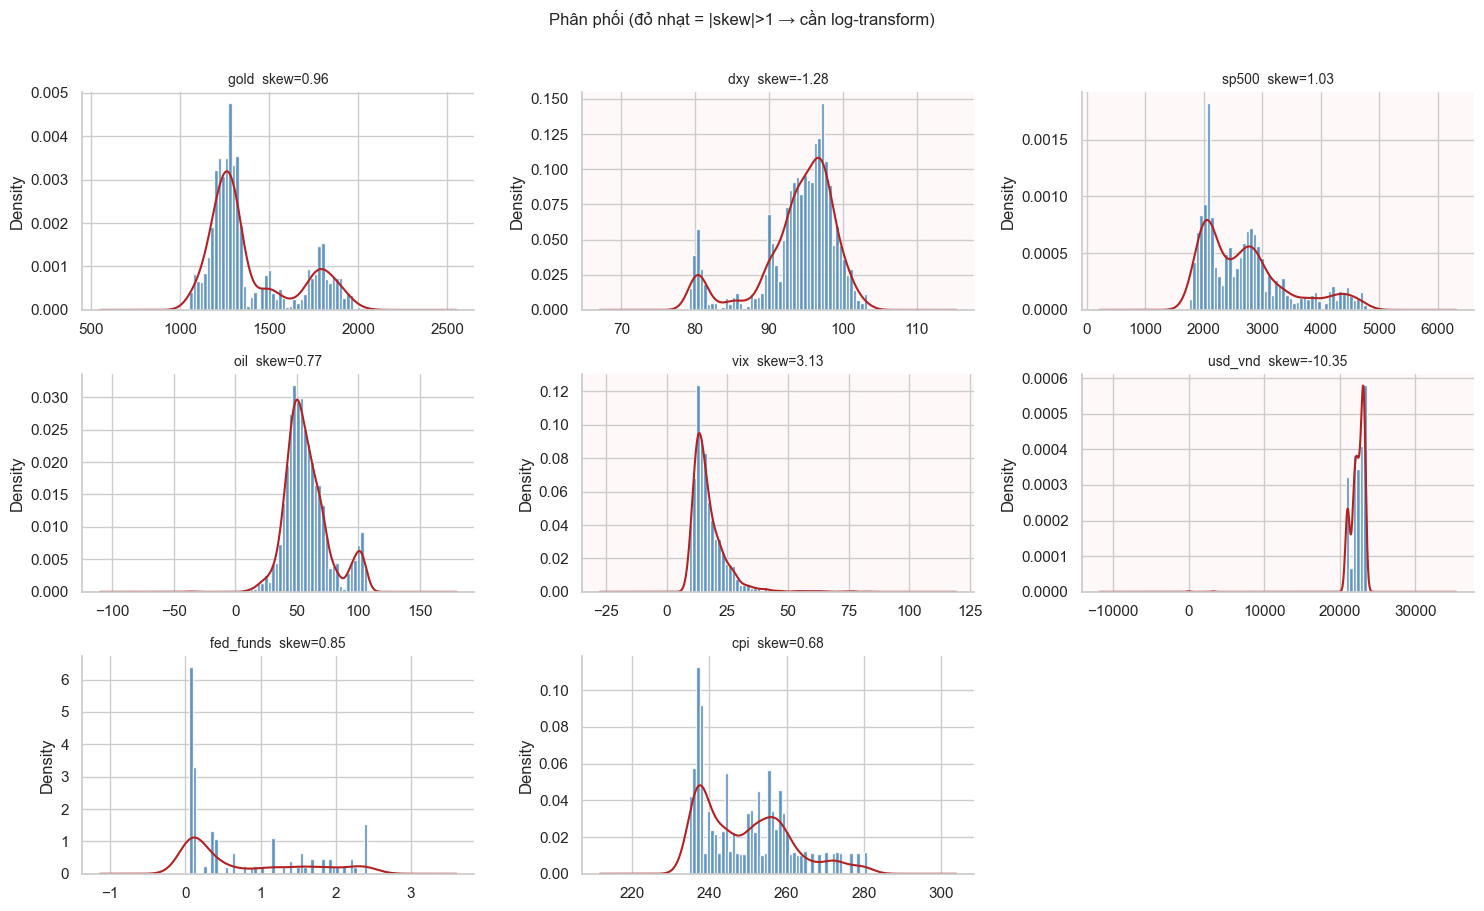

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(15, 9))
axes = axes.flatten()
for i, col in enumerate(NUM_COLS):
    data = train[col].dropna()
    axes[i].hist(data, bins=50, color="steelblue", edgecolor="white", alpha=0.85, density=True)
    data.plot.kde(ax=axes[i], color="firebrick", linewidth=1.5)
    skew = data.skew()
    axes[i].set_title(f"{col}  skew={skew:.2f}", fontsize=10)
    if abs(skew) > 1:
        axes[i].set_facecolor("#fff8f8")
    axes[i].spines[["top","right"]].set_visible(False)
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle("Phân phối (đỏ nhạt = |skew|>1 → cần log-transform)", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

## 4. EDA-3. Kiểm định tính dừng (ADF Test)

In [7]:
def adf_test(series, name):
    clean = series.dropna()
    if len(clean) < 20:
        return
    res = adfuller(clean, maxlag=10, autolag="AIC")
    status = "✅ Dừng" if res[1] < 0.05 else "❌ Cần transform"
    print(f"  {name:<30} | p={res[1]:.4f} | {status}")

print(f"{'Series':<30} | {'p-value':>8} | Kết luận")
print("─" * 55)
print("[Level — dự kiến không dừng]")
for col in NUM_COLS:
    adf_test(df[col].dropna(), f"{col} (level)")

print("\n[Sau transform — dự kiến dừng]")
adf_test(np.log(df["gold"]).diff(),     "gold (log return)")
adf_test(np.log(df["dxy"]).diff(),     "dxy (log return)")
adf_test(np.log(df["sp500"]).diff(),    "sp500 (log return)")
adf_test(np.log(df["oil"]).diff(),      "oil (log return)")
adf_test(np.log(df["usd_vnd"]).diff(), "usd_vnd (log return)")
adf_test(df["fed_funds"].diff(),        "fed_funds (diff)")
adf_test(df["cpi"].pct_change(),        "cpi (pct_change)")

Series                         |  p-value | Kết luận
───────────────────────────────────────────────────────
[Level — dự kiến không dừng]
  gold (level)                   | p=0.9991 | ❌ Cần transform
  dxy (level)                    | p=0.0745 | ❌ Cần transform
  sp500 (level)                  | p=0.9973 | ❌ Cần transform
  oil (level)                    | p=0.1631 | ❌ Cần transform
  vix (level)                    | p=0.0000 | ✅ Dừng
  usd_vnd (level)                | p=0.1241 | ❌ Cần transform
  fed_funds (level)              | p=0.8728 | ❌ Cần transform
  cpi (level)                    | p=1.0000 | ❌ Cần transform

[Sau transform — dự kiến dừng]
  gold (log return)              | p=0.0000 | ✅ Dừng
  dxy (log return)               | p=0.0000 | ✅ Dừng
  sp500 (log return)             | p=0.0000 | ✅ Dừng
  oil (log return)               | p=0.0000 | ✅ Dừng
  usd_vnd (log return)           | p=0.0000 | ✅ Dừng
  fed_funds (diff)               | p=0.0000 | ✅ Dừng
  cpi (pct_change)       

## 5. EDA-4. ACF / PACF — Quyết định độ dài Lag

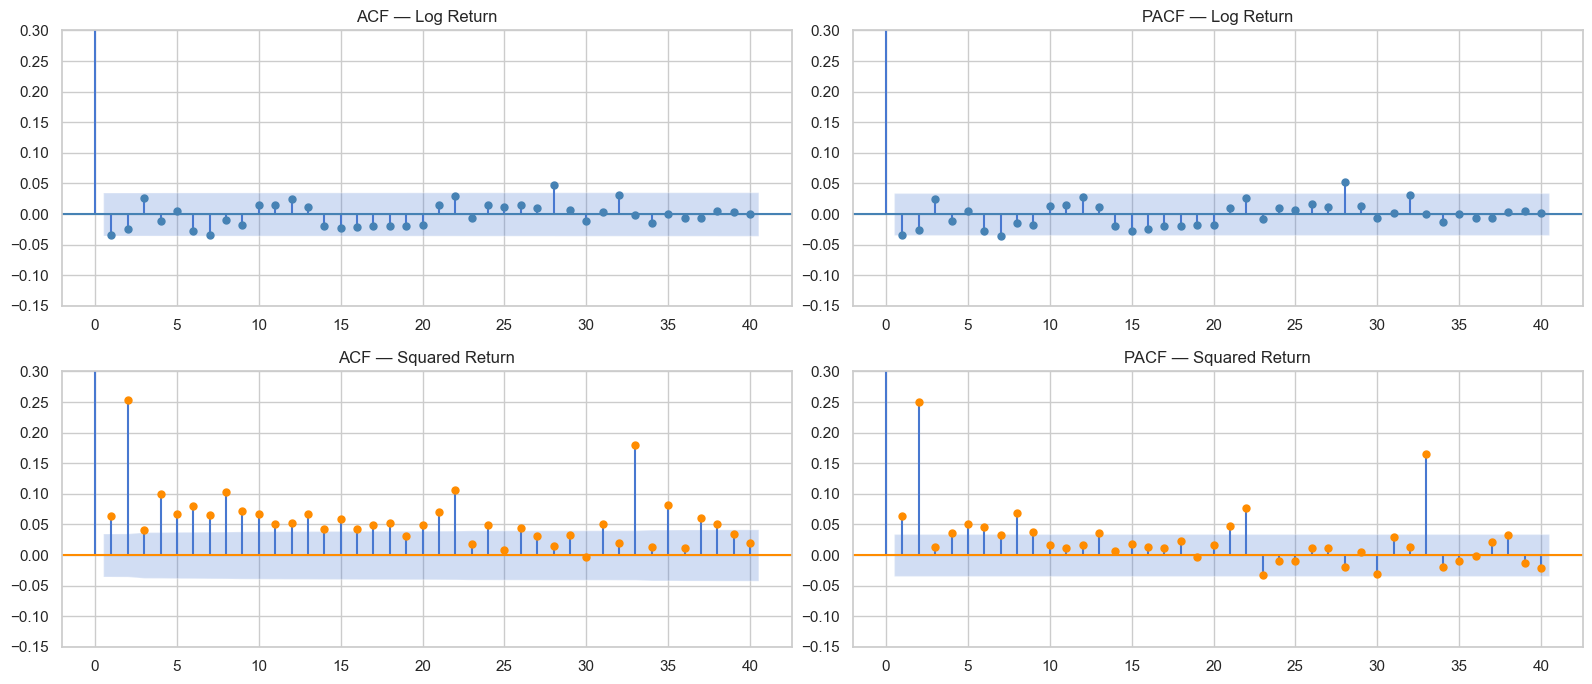

Lag return có ý nghĩa  : [28] → tạo ret_lag cho các lag này
Lag squared có ý nghĩa : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 20, 21, 22, 24, 26, 31, 33, 35, 37, 38] → xác nhận cần rolling vol features


In [8]:
gold_ret = np.log(df["gold"]).diff().dropna()
n        = len(gold_ret)
ci       = 2 / np.sqrt(n)

fig, axes = plt.subplots(2, 2, figsize=(16, 7))

plot_acf(gold_ret, ax=axes[0,0], lags=40,
         title="ACF — Log Return", color="steelblue")

plot_pacf(gold_ret, ax=axes[0,1], lags=40,
         title="PACF — Log Return", color="steelblue")

plot_acf(gold_ret**2, ax=axes[1,0], lags=40,
         title="ACF — Squared Return", color="darkorange")

plot_pacf(gold_ret**2, ax=axes[1,1], lags=40,
         title="PACF — Squared Return", color="darkorange")

for ax in axes.flatten():
    ax.set_ylim(-0.15, 0.30)

plt.tight_layout()
plt.show()

acf_vals     = acf(gold_ret,    nlags=40)[1:]
acf_sq_vals  = acf(gold_ret**2, nlags=40)[1:]
sig_ret_lags = [i+1 for i, v in enumerate(acf_vals)    if abs(v) > ci]
sig_vol_lags = [i+1 for i, v in enumerate(acf_sq_vals) if abs(v) > ci]

print(f"Lag return có ý nghĩa  : {sig_ret_lags} → tạo ret_lag cho các lag này")
print(f"Lag squared có ý nghĩa : {sig_vol_lags} → xác nhận cần rolling vol features")

## 6. EDA-5. Outlier — IQR×3

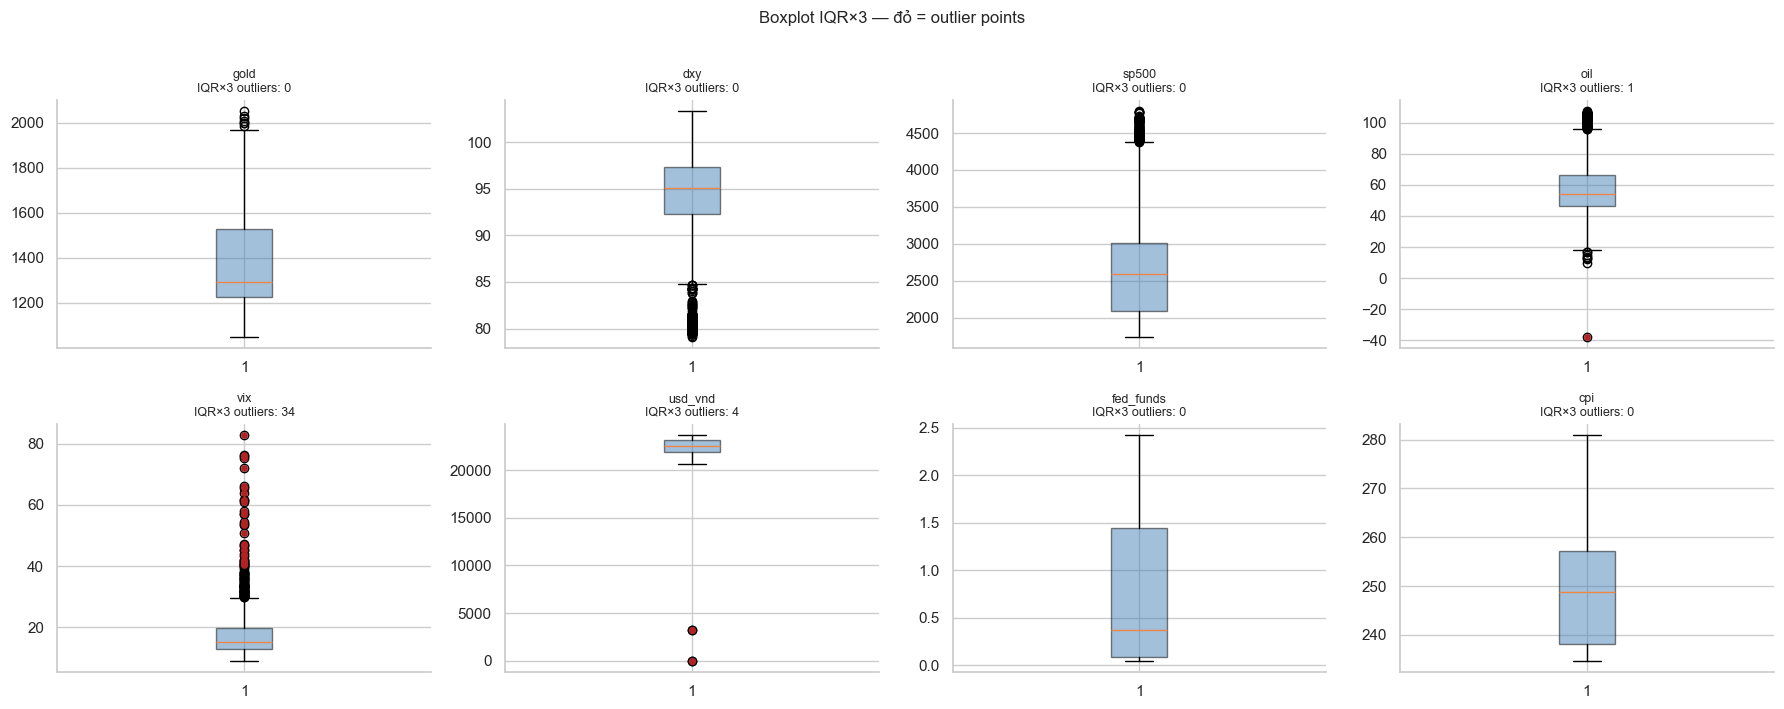

Quyết định:
  gold, vix, fed_funds, cpi → KHÔNG cap
  sp500, dxy, oil            → cap IQR×3
  usd_vnd                    → fix đơn vị (×1000) rồi cap


In [9]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
axes = axes.flatten()
for i, col in enumerate(NUM_COLS):
    q1, q3  = train[col].quantile([0.25, 0.75])
    iqr     = q3 - q1
    lo, hi  = q1 - 3*iqr, q3 + 3*iqr
    n_out   = ((train[col] < lo) | (train[col] > hi)).sum()
    axes[i].boxplot(train[col].dropna(), patch_artist=True,
                    boxprops=dict(facecolor="steelblue", alpha=0.5))
    axes[i].set_title(f"{col}\nIQR×3 outliers: {n_out}", fontsize=9)
    outlier_vals = train[col][(train[col] < lo) | (train[col] > hi)]
    if len(outlier_vals) > 0:
        axes[i].scatter([1]*len(outlier_vals), outlier_vals,
                       color="firebrick", zorder=5, s=15)
    axes[i].spines[["top","right"]].set_visible(False)
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle("Boxplot IQR×3 — đỏ = outlier points", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

print("Quyết định:")
print("  gold, vix, fed_funds, cpi → KHÔNG cap")
print("  sp500, dxy, oil            → cap IQR×3")
print("  usd_vnd                    → fix đơn vị (×1000) rồi cap")

## 7. EDA-6. Tương quan Returns (Stationary)

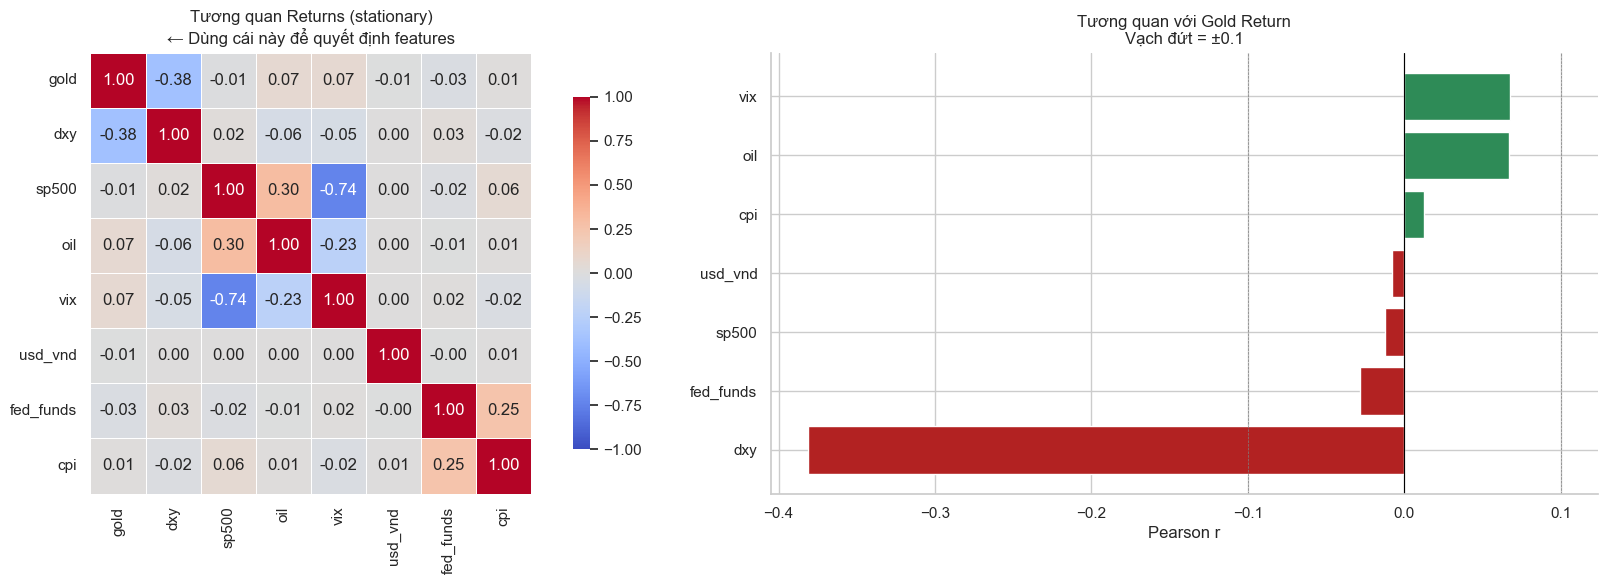

In [10]:
train_ret = pd.DataFrame({
    "gold":      np.log(train["gold"]).diff(),
    "dxy":       np.log(train["dxy"]).diff(),
    "sp500":     np.log(train["sp500"]).diff(),
    "oil":       np.log(train["oil"]).diff(),
    "vix":       np.log(train["vix"].clip(lower=0.01)).diff(),
    "usd_vnd":   np.log(train["usd_vnd"]).diff(),
    "fed_funds": train["fed_funds"].diff(),
    "cpi":       train["cpi"].pct_change(),
}).dropna()

corr = train_ret.corr()
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, linewidths=0.5, ax=axes[0],
            cbar_kws={"shrink": 0.8}, vmin=-1, vmax=1)
axes[0].set_title("Tương quan Returns (stationary)\n← Dùng cái này để quyết định features")

gold_corr = corr["gold"].drop("gold").sort_values()
colors    = ["firebrick" if x < 0 else "seagreen" for x in gold_corr]
axes[1].barh(gold_corr.index, gold_corr.values, color=colors, edgecolor="white")
axes[1].axvline(0,    color="black", linewidth=0.8)
axes[1].axvline( 0.1, color="gray",  linewidth=0.5, linestyle="--")
axes[1].axvline(-0.1, color="gray",  linewidth=0.5, linestyle="--")
axes[1].set_title("Tương quan với Gold Return\nVạch đứt = ±0.1")
axes[1].set_xlabel("Pearson r")
axes[1].spines[["top","right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [11]:
print("=== Cặp cross-features có |corr| > 0.6 ===")
found = False
for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        r = abs(corr.iloc[i, j])
        if r > 0.6 and "gold" not in [corr.columns[i], corr.columns[j]]:
            print(f"  {corr.columns[i]} ↔ {corr.columns[j]}: r={corr.iloc[i,j]:.3f}")
            found = True
if not found:
    print("  Không có → không cần lo multicollinearity")

=== Cặp cross-features có |corr| > 0.6 ===
  sp500 ↔ vix: r=-0.736


## 8. EDA-7. Rolling Correlation — Dynamic Relationship

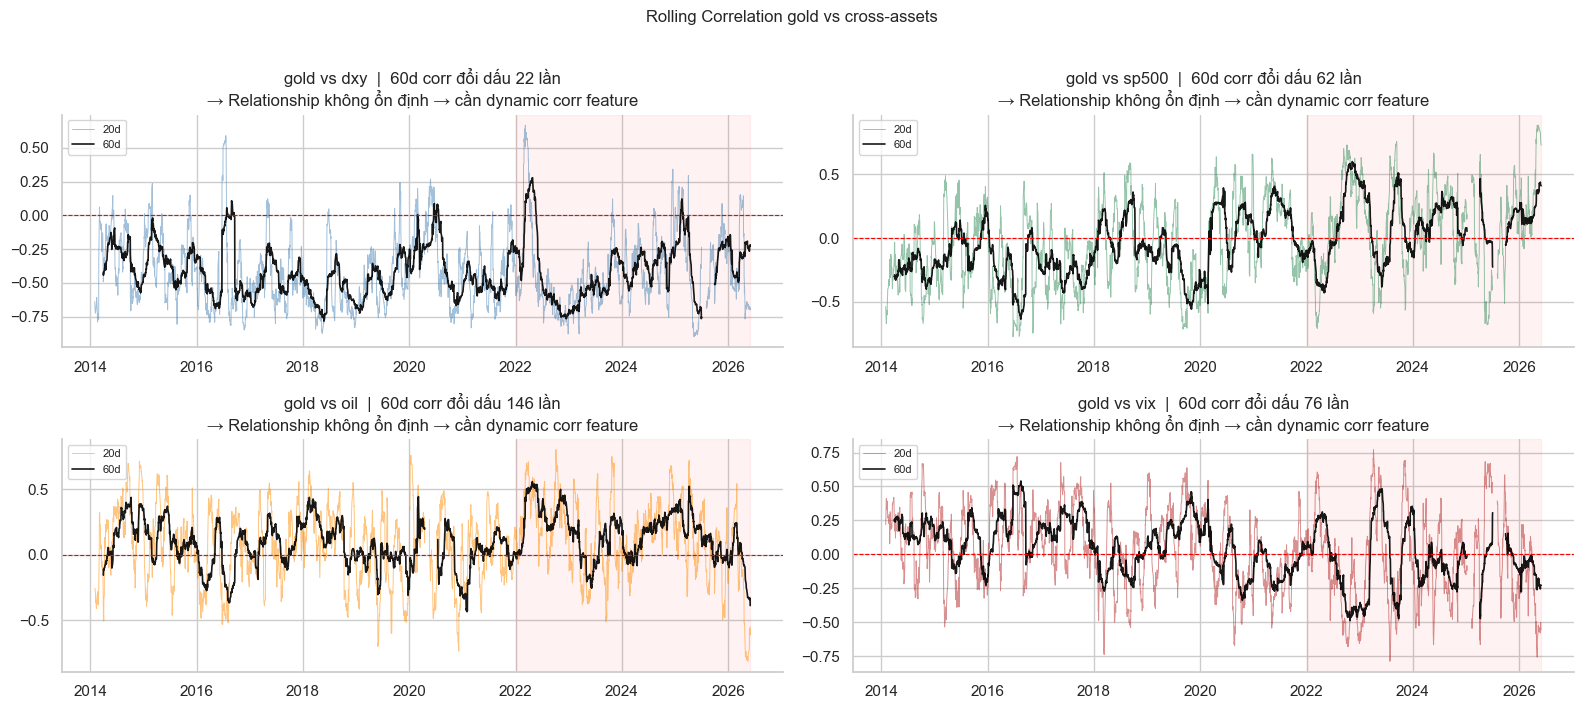

In [12]:
gold_ret_s = np.log(df["gold"]).diff()
fig, axes  = plt.subplots(2, 2, figsize=(16, 7))
pairs = [("dxy","steelblue"),("sp500","seagreen"),("oil","darkorange"),("vix","firebrick")]

for ax, (col, color) in zip(axes.flatten(), pairs):
    other = np.log(df[col].clip(lower=0.01) if col == "vix" else df[col]).diff()
    r20   = gold_ret_s.rolling(20).corr(other)
    r60   = gold_ret_s.rolling(60).corr(other)
    ax.plot(df["date"], r20, alpha=0.5, linewidth=0.7, color=color, label="20d")
    ax.plot(df["date"], r60, alpha=0.9, linewidth=1.2, color="black", label="60d")
    ax.axhline(0, color="red", linestyle="--", linewidth=0.8)
    ax.axvspan(pd.Timestamp(SPLIT_DATE), df["date"].max(), alpha=0.05, color="red")
    n_flip = ((r60 > 0).astype(int).diff().abs().sum())
    ax.set_title(f"gold vs {col}  |  60d corr đổi dấu {n_flip:.0f} lần\n"
                 f"{'→ Relationship không ổn định → cần dynamic corr feature' if n_flip > 5 else '→ Khá ổn định'}")
    ax.legend(fontsize=8)
    ax.spines[["top","right"]].set_visible(False)

plt.suptitle("Rolling Correlation gold vs cross-assets", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

In [13]:
from statsmodels.tsa.stattools import acf, pacf
acf_values  = acf(gold_ret, nlags=20, alpha=0.05)
pacf_values = pacf(gold_ret, nlags=20, alpha=0.05)

print("=== Lag có ACF ý nghĩa (|acf| > 2/sqrt(n)) ===")
n = len(gold_ret)
threshold = 2 / np.sqrt(n)
sig_lags = [i for i, v in enumerate(acf_values[0][1:], 1) if abs(v) > threshold]
print(f"  Significant lags: {sig_lags[:10]}")
print(f"  → Sẽ tạo ret_lag cho các lag: {sig_lags[:10] if sig_lags else 'không có lag rõ ràng'}")

print("\n=== Volatility Clustering (Squared Return ACF) ===")
sq_acf = acf(gold_ret**2, nlags=20)
sig_vol_lags = [i for i, v in enumerate(sq_acf[1:], 1) if abs(v) > threshold]
if sig_vol_lags:
    print(f"  Confirmed volatility clustering ở lag: {sig_vol_lags[:8]}")
    print("  → Cần tạo rolling_vol features (vol5, vol10, vol20, vol60)")
    print("  → Cần tạo vol_regime, vol_of_vol để capture persistence")
else:
    print("  Không có clustering rõ rệt")

=== Lag có ACF ý nghĩa (|acf| > 2/sqrt(n)) ===
  Significant lags: []
  → Sẽ tạo ret_lag cho các lag: không có lag rõ ràng

=== Volatility Clustering (Squared Return ACF) ===
  Confirmed volatility clustering ở lag: [1, 2, 3, 4, 5, 6, 7, 8]
  → Cần tạo rolling_vol features (vol5, vol10, vol20, vol60)
  → Cần tạo vol_regime, vol_of_vol để capture persistence


## 9. EDA-8. Feature Relevance theo Horizon (90d và 252d)

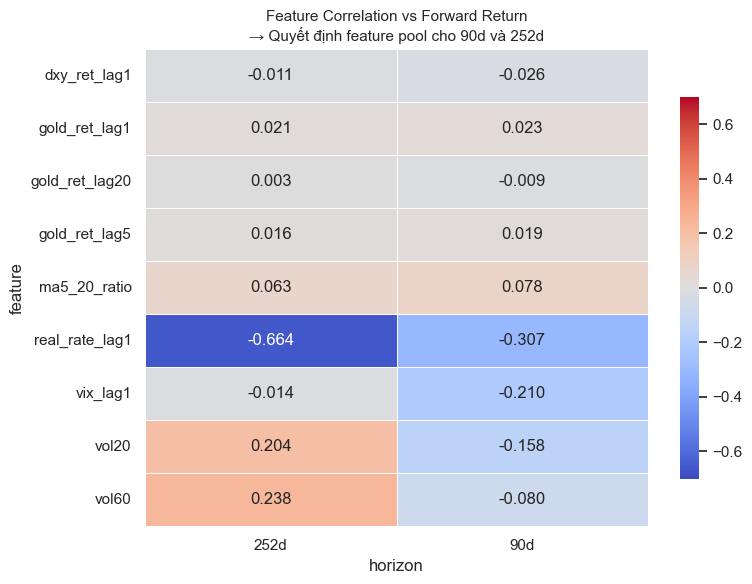

horizon           252d     90d
feature                       
dxy_ret_lag1   -0.0111 -0.0261
gold_ret_lag1   0.0207  0.0234
gold_ret_lag20  0.0031 -0.0086
gold_ret_lag5   0.0156  0.0191
ma5_20_ratio    0.0628  0.0779
real_rate_lag1 -0.6642 -0.3066
vix_lag1       -0.0138 -0.2104
vol20           0.2040 -0.1579
vol60           0.2383 -0.0805

Insight:
  real_rate_lag1: signal MẠNH ở 252d (r=-0.664) → feature quan trọng nhất dài hạn
  vix_lag1: nhất quán ở cả 90d lẫn 252d → giữ cho cả 2
  vol20/vol60: đổi dấu ở 252d → dùng khác nhau tùy horizon


In [14]:
FEATURES_TO_TEST = {
    "gold_ret_lag1":  np.log(train["gold"]).diff().shift(1),
    "gold_ret_lag5":  np.log(train["gold"]).diff().shift(5),
    "gold_ret_lag20": np.log(train["gold"]).diff().shift(20),
    "vol20":          np.log(train["gold"]).diff().rolling(20).std() * np.sqrt(252),
    "vol60":          np.log(train["gold"]).diff().rolling(60).std() * np.sqrt(252),
    "dxy_ret_lag1":   np.log(train["dxy"]).diff().shift(1),
    "vix_lag1":       train["vix"].shift(1),
    "real_rate_lag1": (train["fed_funds"] - train["cpi"].pct_change()*100).shift(1),
    "ma5_20_ratio":   train["gold"].rolling(5).mean() / train["gold"].rolling(20).mean(),
}

rows = []
for h_name, h in [("90d", 90), ("252d", 252)]:
    fwd = np.log(train["gold"]).diff(-h)
    for feat_name, feat_s in FEATURES_TO_TEST.items():
        tmp = pd.concat([feat_s, fwd], axis=1).dropna()
        r   = tmp.corr().iloc[0, 1] if len(tmp) >= 50 else 0.0
        rows.append({"feature": feat_name, "horizon": h_name, "corr": r})

corr_df = pd.DataFrame(rows).pivot(index="feature", columns="horizon", values="corr")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_df, annot=True, fmt=".3f", cmap="coolwarm",
            center=0, linewidths=0.5, ax=ax,
            cbar_kws={"shrink": 0.8}, vmin=-0.7, vmax=0.7)
ax.set_title("Feature Correlation vs Forward Return\n"
             "→ Quyết định feature pool cho 90d và 252d", fontsize=11)
plt.tight_layout()
plt.show()
print(corr_df.round(4).to_string())
print("\nInsight:")
print("  real_rate_lag1: signal MẠNH ở 252d (r=-0.664) → feature quan trọng nhất dài hạn")
print("  vix_lag1: nhất quán ở cả 90d lẫn 252d → giữ cho cả 2")
print("  vol20/vol60: đổi dấu ở 252d → dùng khác nhau tùy horizon")

## 10. EDA-9. Phân tích Macro (Fed & Real Rate)

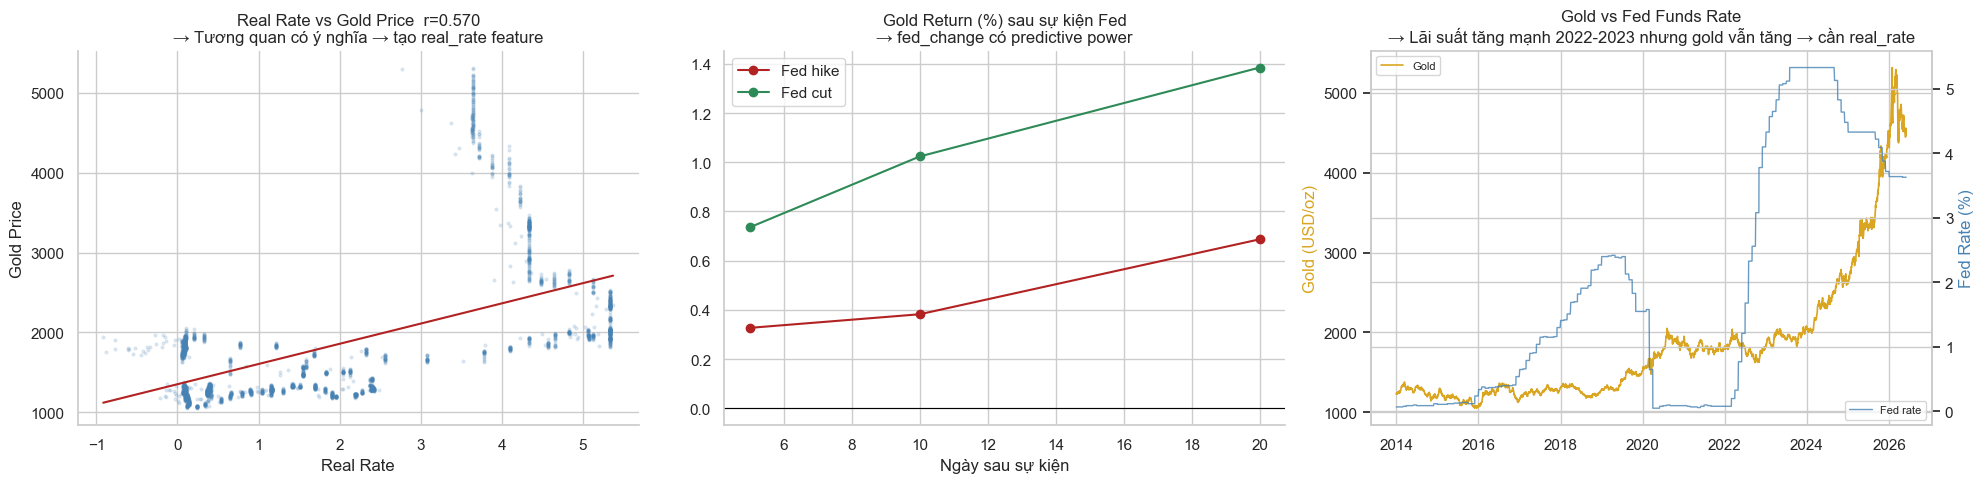

In [15]:
df_m             = df.copy()
df_m["cpi_mom"]  = df_m["cpi"].pct_change() * 100
df_m["real_rate"]= df_m["fed_funds"] - df_m["cpi_mom"]
df_m["fed_chg"]  = df_m["fed_funds"].diff()

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Real rate vs Gold price (level corr để visualize)
r_real = df_m[["real_rate","gold"]].dropna().corr().iloc[0,1]
axes[0].scatter(df_m["real_rate"].dropna(),
                df_m["gold"][df_m["real_rate"].notna()],
                alpha=0.15, s=4, color="steelblue")
z = np.polyfit(df_m["real_rate"].dropna(),
               df_m["gold"][df_m["real_rate"].notna()], 1)
xl = np.linspace(df_m["real_rate"].min(), df_m["real_rate"].max(), 100)
axes[0].plot(xl, np.poly1d(z)(xl), color="firebrick", linewidth=1.5)
axes[0].set_title(f"Real Rate vs Gold Price  r={r_real:.3f}\n"
                  f"→ {'Tương quan có ý nghĩa → tạo real_rate feature' if abs(r_real)>0.1 else 'Tương quan yếu'}")
axes[0].set_xlabel("Real Rate")
axes[0].set_ylabel("Gold Price")
axes[0].spines[["top","right"]].set_visible(False)

# Gold return sau sự kiện Fed hike/cut
events = []
for date in df_m.loc[df_m["fed_chg"] != 0, "date"]:
    idx = df_m[df_m["date"] == date].index
    if len(idx) == 0: continue
    i = idx[0]
    for h in [5, 10, 20]:
        if i + h < len(df_m):
            ret = np.log(df_m.loc[i+h, "gold"] / df_m.loc[i, "gold"])
            events.append({"h": h, "dir": "hike" if df_m.loc[i,"fed_chg"]>0 else "cut", "ret": ret})

ev_df = pd.DataFrame(events)
if len(ev_df) > 0:
    for dname, color in [("hike","firebrick"),("cut","seagreen")]:
        sub = ev_df[ev_df["dir"]==dname]
        if len(sub) > 0:
            axes[1].plot(sub.groupby("h")["ret"].mean()*100,
                        marker="o", color=color, label=f"Fed {dname}")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Gold Return (%) sau sự kiện Fed\n→ fed_change có predictive power")
axes[1].set_xlabel("Ngày sau sự kiện")
axes[1].legend()
axes[1].spines[["top","right"]].set_visible(False)

# Fed funds vs Gold (time series)
ax2 = axes[2].twinx()
axes[2].plot(df_m["date"], df_m["gold"],      color="goldenrod", linewidth=1.2, label="Gold")
ax2.plot(    df_m["date"], df_m["fed_funds"], color="steelblue", linewidth=1.0, label="Fed rate", alpha=0.8)
axes[2].set_title("Gold vs Fed Funds Rate\n→ Lãi suất tăng mạnh 2022-2023 nhưng gold vẫn tăng → cần real_rate")
axes[2].set_ylabel("Gold (USD/oz)", color="goldenrod")
ax2.set_ylabel("Fed Rate (%)", color="steelblue")
axes[2].legend(loc="upper left", fontsize=8)
ax2.legend(loc="lower right", fontsize=8)
axes[2].spines[["top"]].set_visible(False)

plt.tight_layout()
plt.show()


## 11. EDA-10. Volatility Regime

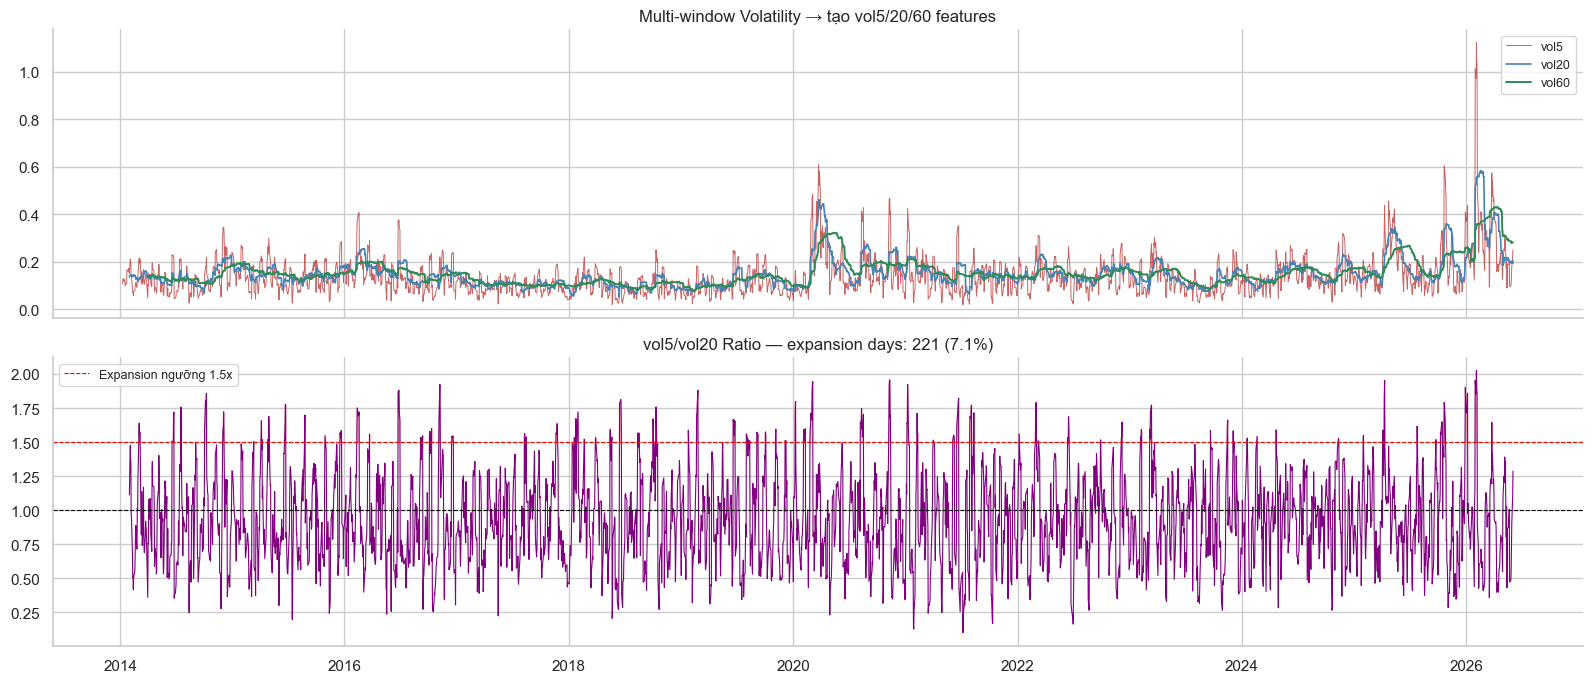

In [16]:
gold_ret_all = np.log(df["gold"]).diff()
vol5  = gold_ret_all.rolling(5).std()  * np.sqrt(252)
vol20 = gold_ret_all.rolling(20).std() * np.sqrt(252)
vol60 = gold_ret_all.rolling(60).std() * np.sqrt(252)
v_ratio = vol5 / (vol20 + 1e-9)

fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
axes[0].plot(df["date"], vol5,  color="firebrick", linewidth=0.7, alpha=0.7, label="vol5")
axes[0].plot(df["date"], vol20, color="steelblue", linewidth=1.2, label="vol20")
axes[0].plot(df["date"], vol60, color="seagreen",  linewidth=1.4, label="vol60")
axes[0].set_title("Multi-window Volatility → tạo vol5/20/60 features")
axes[0].legend(fontsize=9)
axes[0].spines[["top","right"]].set_visible(False)

axes[1].plot(df["date"], v_ratio, color="purple", linewidth=0.8)
axes[1].axhline(1.0, color="black",  linestyle="--", linewidth=0.8)
axes[1].axhline(1.5, color="red",    linestyle="--", linewidth=0.8, label="Expansion ngưỡng 1.5x")
axes[1].fill_between(df["date"], 1.5, v_ratio, where=(v_ratio>1.5), alpha=0.2, color="red")
axes[1].set_title(f"vol5/vol20 Ratio — expansion days: {(v_ratio>1.5).sum()} ({(v_ratio>1.5).mean()*100:.1f}%)")
axes[1].legend(fontsize=9)
axes[1].spines[["top","right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 12. EDA-11. Phân tích Target 90d và 252d

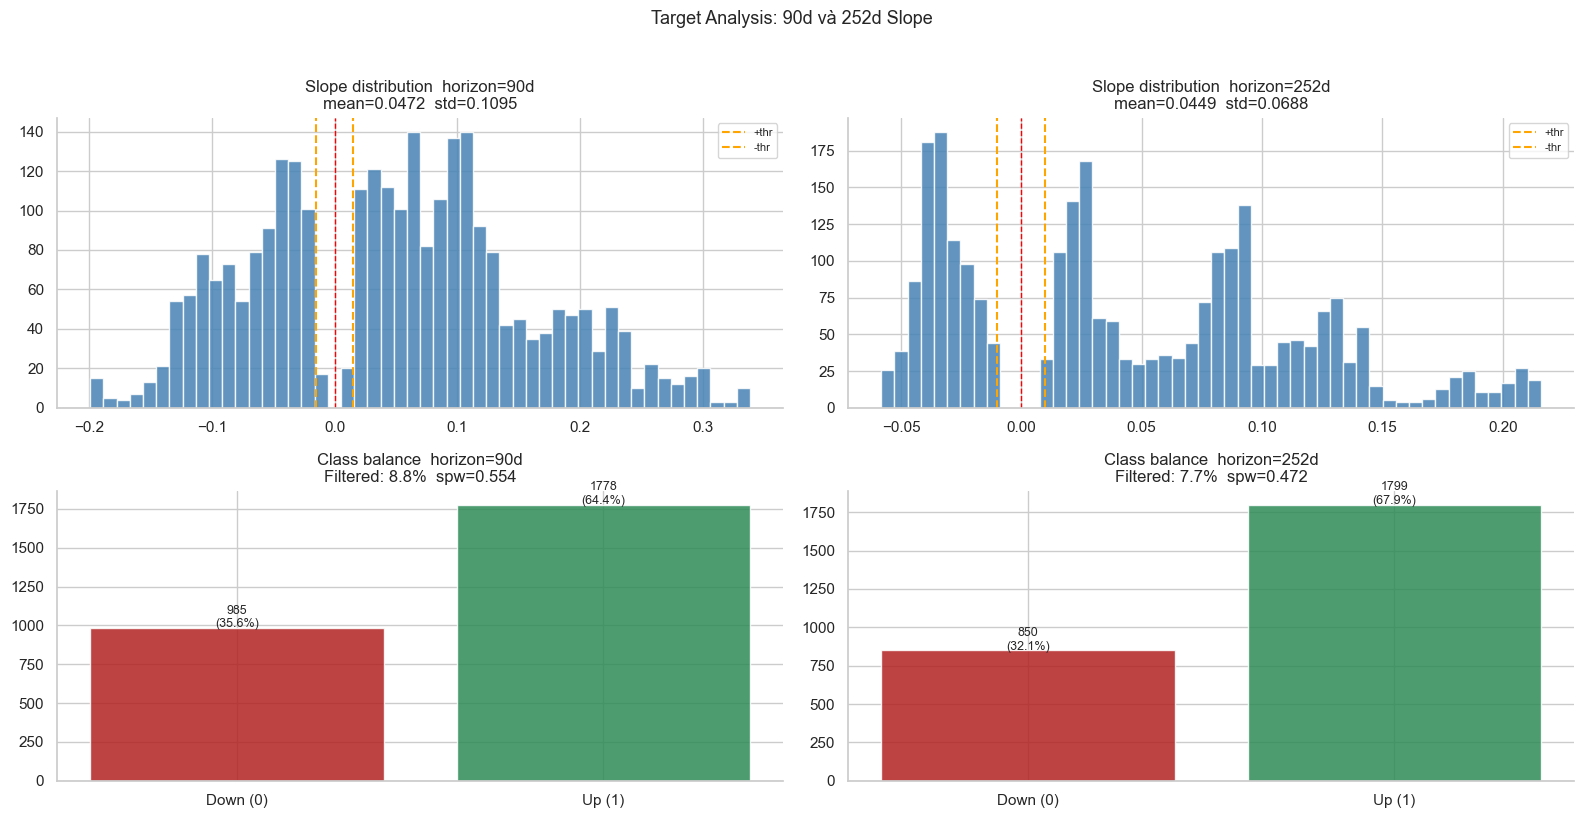


=== Target Summary ===
     valid_samples     up_%   down_%  filtered_%  scale_pos_weight  mean_slope  std_slope
90          2763.0  64.3503  35.6497      8.8420            0.5540      0.0005     0.0011
252         2649.0  67.9124  32.0876      7.6682            0.4725      0.0004     0.0007

→ scale_pos_weight sẽ được dùng trong XGB/LGBM ở notebook 03


In [17]:
def compute_slope_target(prices, horizon, threshold):
    log_p  = np.log(prices.values)
    n      = len(log_p)
    slopes = np.full(n, np.nan)
    x      = np.arange(horizon, dtype=float)
    xm     = x.mean()
    xss    = ((x - xm)**2).sum()
    for i in range(n - horizon):
        y = log_p[i:i+horizon]
        slopes[i] = ((x - xm) * (y - y.mean())).sum() / xss
    targets = np.where(slopes > threshold, 1.,
              np.where(slopes < -threshold, 0., np.nan))
    return slopes, targets

HORIZON_CONFIG = {
    90:  0.00015,
    252: 0.0001,
}

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
target_info = {}

for col_idx, (h, thr) in enumerate(HORIZON_CONFIG.items()):
    slopes, targets = compute_slope_target(df["gold"], h, thr)
    valid   = ~np.isnan(targets)
    up_pct  = (targets[valid] == 1).mean() * 100
    dn_pct  = 100 - up_pct

    target_info[h] = {
        "valid_samples": valid.sum(),
        "up_%":          up_pct,
        "down_%":        dn_pct,
        "filtered_%":    (~valid[:len(df)-h]).mean() * 100,
        "scale_pos_weight": dn_pct / up_pct,
        "mean_slope":    np.nanmean(slopes[valid]),
        "std_slope":     np.nanstd(slopes[valid]),
    }

    # Histogram slope
    axes[0, col_idx].hist(slopes[valid]*100, bins=50,
                          color="steelblue", edgecolor="white", alpha=0.85)
    axes[0, col_idx].axvline( thr*100, color="orange", linestyle="--", linewidth=1.5, label="+thr")
    axes[0, col_idx].axvline(-thr*100, color="orange", linestyle="--", linewidth=1.5, label="-thr")
    axes[0, col_idx].axvline(0, color="red", linestyle="--", linewidth=1)
    axes[0, col_idx].set_title(f"Slope distribution  horizon={h}d\n"
                               f"mean={np.nanmean(slopes[valid])*100:.4f}  "
                               f"std={np.nanstd(slopes[valid])*100:.4f}")
    axes[0, col_idx].legend(fontsize=8)
    axes[0, col_idx].spines[["top","right"]].set_visible(False)

    # Class balance
    vals   = [(targets[valid]==0).sum(), (targets[valid]==1).sum()]
    bars   = axes[1, col_idx].bar(["Down (0)","Up (1)"], vals,
                                   color=["firebrick","seagreen"], edgecolor="white", alpha=0.85)
    for bar, v in zip(bars, vals):
        axes[1, col_idx].text(bar.get_x()+bar.get_width()/2, bar.get_height()+3,
                              f"{v}\n({v/valid.sum()*100:.1f}%)", ha="center", fontsize=9)
    axes[1, col_idx].set_title(f"Class balance  horizon={h}d\n"
                               f"Filtered: {(~valid[:len(df)-h]).mean()*100:.1f}%  "
                               f"spw={dn_pct/up_pct:.3f}")
    axes[1, col_idx].spines[["top","right"]].set_visible(False)

plt.suptitle("Target Analysis: 90d và 252d Slope", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print("\n=== Target Summary ===")
print(pd.DataFrame(target_info).T.round(4).to_string())
print("\n→ scale_pos_weight sẽ được dùng trong XGB/LGBM ở notebook 03")

## 13. Preprocessing

In [18]:
PROCESSED_DIR = os.path.join(ROOT, "data", "processed")
os.makedirs(PROCESSED_DIR, exist_ok=True)

HORIZON_CONFIG = {
    90:  {"threshold": 0.00015, "name": "90d"},
    252: {"threshold": 0.0001,  "name": "252d"},
}

In [19]:
def preprocess(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df = df.dropna(subset=["gold"])
    for col in MACRO_COLS:
        df[col] = df[col].ffill()
    for col in [c for c in MARKET_COLS if c != "gold"]:
        df[col] = df[col].ffill()
    df["usd_vnd"] = df["usd_vnd"].ffill()
    df.loc[df["usd_vnd"] < 1000, "usd_vnd"] *= 1000
    for col in ["sp500", "dxy", "oil", "usd_vnd"]:
        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr    = q3 - q1
        lo, hi = q1 - 3*iqr, q3 + 3*iqr
        n = ((df[col] < lo) | (df[col] > hi)).sum()
        if n > 0:
            df[col] = df[col].clip(lo, hi)
            print(f"  Capped {col}: {n} rows -> [{lo:.2f}, {hi:.2f}]")
    df = df.dropna(subset=MARKET_COLS)
    return df.sort_values("date").reset_index(drop=True)


df_raw   = pd.read_csv(FILE_RAW_DATASET, parse_dates=["date"])
df_raw   = df_raw.sort_values("date").reset_index(drop=True)
df_clean = preprocess(df_raw)

print(f"Shape after preprocessing : {df_clean.shape}")
print(f"Null remaining:\n{df_clean[NUM_COLS].isnull().sum().to_string()}")

  Capped oil: 1 rows -> [-28.65, 156.99]
  Capped usd_vnd: 2 rows -> [18040.00, 27945.00]
Shape after preprocessing : (3121, 9)
Null remaining:
gold         0
dxy          0
sp500        0
oil          0
vix          0
usd_vnd      0
fed_funds    0
cpi          0


## 14. Compute Targets

Horizon          Up     Down   Filtered      spw
----------------------------------------------
90d         1778(64.4%)    985(35.6%)     11.5%    0.554
252d        1799(67.9%)    850(32.1%)     15.1%    0.472


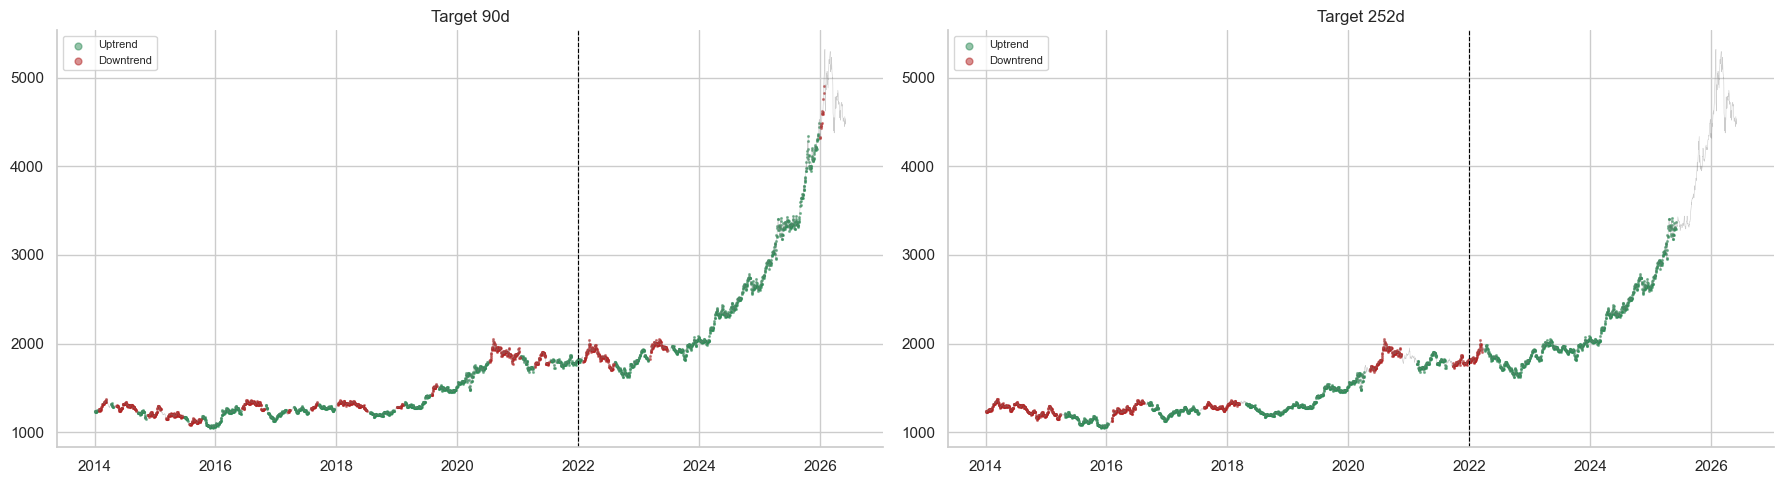

In [20]:
def compute_slope_target(prices: pd.Series, horizon: int, threshold: float):
    log_p  = np.log(prices.values)
    n      = len(log_p)
    slopes = np.full(n, np.nan)
    x      = np.arange(horizon, dtype=float)
    xm     = x.mean()
    xss    = ((x - xm)**2).sum()
    for i in range(n - horizon):
        y         = log_p[i:i+horizon]
        slopes[i] = ((x - xm) * (y - y.mean())).sum() / xss
    targets = np.where(slopes > threshold, 1.,
              np.where(slopes < -threshold, 0., np.nan))
    return (
        pd.Series(slopes,  index=prices.index, name=f"slope_{horizon}d"),
        pd.Series(targets, index=prices.index, name=f"target_{horizon}d"),
    )


print(f"{'Horizon':<10} {'Up':>8} {'Down':>8} {'Filtered':>10} {'spw':>8}")
print("-" * 46)
for h, cfg in HORIZON_CONFIG.items():
    slope_s, target_s = compute_slope_target(df_clean["gold"], h, cfg["threshold"])
    df_clean[f"slope_{h}d"]  = slope_s
    df_clean[f"target_{h}d"] = target_s
    valid = target_s.notna()
    up    = (target_s[valid] == 1).sum()
    dn    = (target_s[valid] == 0).sum()
    cfg["spw"] = dn / up
    print(f"{str(h)+'d':<10} {up:>5}({up/(up+dn)*100:.1f}%)  "
          f"{dn:>5}({dn/(up+dn)*100:.1f}%)  "
          f"{100-valid.mean()*100:>7.1f}%  {dn/up:>7.3f}")

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, (h, cfg) in zip(axes, HORIZON_CONFIG.items()):
    tcol = f"target_{h}d"
    df_p = df_clean[df_clean[tcol].notna()].copy()
    ax.plot(df_clean["date"], df_clean["gold"], color="gray", linewidth=0.4, alpha=0.4)
    ax.scatter(df_p.loc[df_p[tcol]==1,"date"], df_p.loc[df_p[tcol]==1,"gold"],
               s=1.5, color="seagreen", alpha=0.5, label="Uptrend")
    ax.scatter(df_p.loc[df_p[tcol]==0,"date"], df_p.loc[df_p[tcol]==0,"gold"],
               s=1.5, color="firebrick", alpha=0.5, label="Downtrend")
    ax.axvline(pd.Timestamp(SPLIT_DATE), color="black", linestyle="--", linewidth=0.8)
    ax.set_title(f"Target {h}d")
    ax.legend(fontsize=8, markerscale=4)
    ax.spines[["top","right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 15. Feature Engineering

In [21]:
def build_features(df: pd.DataFrame, max_horizon: int) -> pd.DataFrame:
    """
    Feature Engineering — chỉ giữ features có evidence từ EDA và feature importance.

    Nguyên tắc cắt:
      - Lag returns (ret_lag1..20): ACF gần 0 ở tất cả lag → bỏ hầu hết
      - Rolling vol thuần (vol5/10/20/60): importance ≈ 0 ở 90d, thấp ở 252d
        → chỉ giữ vol60 (long-term regime) và vol5_20_ratio (expansion signal)
      - Technical oscillators (RSI, stoch, bb, roc): importance thấp cả 2 horizon
        → bỏ hết, chỉ giữ zscore60 (mean reversion) và ma20_50_ratio (trend)
      - Seasonality: chỉ month_cos quan trọng ở 90d → giữ sin/cos tháng, bỏ weekday
      - Macro: top features cả 2 horizon → giữ đầy đủ
      - Cross-asset: corr_gold_dxy quan trọng (90d), corr_gold_sp500 (252d)
        → giữ dynamic corr + vol của dxy/vix/sp500
    """
    df = df.copy().sort_values("date").reset_index(drop=True)
    g  = df["gold"]

    # ══════════════════════════════════════════════════════
    # 1. GOLD RETURN — chỉ ret_lag1 và ret_mean20
    # ══════════════════════════════════════════════════════
    # ACF log return: không có lag nào vượt CI → lag ngắn gần random walk
    # Chỉ giữ lag1 (momentum 1 ngày) và mean20 (momentum trung hạn)
    df["gold_ret1"]   = np.log(g / g.shift(1))
    df["ret_lag1"]    = df["gold_ret1"].shift(1)
    df["ret_mean20"]  = df["gold_ret1"].rolling(20).mean()

    # ══════════════════════════════════════════════════════
    # 2. VOLATILITY — chỉ những window có ý nghĩa
    # ══════════════════════════════════════════════════════
    # vol60: long-term regime vol — quan trọng ở 252d (importance ~0.03)
    # vol5_20_ratio: expansion signal — EDA xác nhận, vẫn giữ
    # vol_regime_rank: normalize vol qua thời gian tránh bias
    # Bỏ: vol5, vol10, vol20 thuần (importance ≈ 0 ở 90d, thấp ở 252d)
    df["vol20"] = df["gold_ret1"].rolling(20).std() * np.sqrt(252)  # cần cho ratio
    df["vol60"] = df["gold_ret1"].rolling(60).std() * np.sqrt(252)
    df["vol5"]  = df["gold_ret1"].rolling(5).std()  * np.sqrt(252)  # cần cho ratio
    df["vol5_20_ratio"]   = df["vol5"]  / (df["vol20"] + 1e-9)
    df["vol_regime_rank"] = df["vol20"].rolling(252).rank(pct=True)
    df = df.drop(columns=["vol5"], errors="ignore")  # chỉ dùng để tính ratio

    # ══════════════════════════════════════════════════════
    # 3. TECHNICAL — chỉ scale-free, mean-reversion focused
    # ══════════════════════════════════════════════════════
    # ma20_50_ratio: trend direction, scale-free — importance nhỏ nhưng ổn định
    # zscore60: mean reversion signal dài hạn — xuất hiện trong top 252d
    # price_pos_50: vị trí giá vs MA50, scale-free — xuất hiện top 252d
    # Bỏ: RSI, stoch, bb, roc, adx — importance gần 0 cả 2 horizon
    for w in [20, 50]:
        df[f"ma{w}"] = g.rolling(w).mean()
    df["ma20_50_ratio"] = df["ma20"] / (df["ma50"] + 1e-9)
    df["price_pos_50"]  = (g - df["ma50"]) / (df["ma50"] + 1e-9)
    df["zscore60"]      = (g - g.rolling(60).mean()) / (g.rolling(60).std() + 1e-9)
    df = df.drop(columns=["ma20", "ma50"], errors="ignore")

    # ══════════════════════════════════════════════════════
    # 4. CROSS-ASSET — dynamic relationship
    # ══════════════════════════════════════════════════════
    # dxy: inverse predictor mạnh nhất (r=-0.38), dxy_vol20 top 90d & 252d
    # vix: vix_log và vix_vol quan trọng ở 252d
    # sp500: corr60_gold_sp500 và sp500_ret_mean20 xuất hiện top 252d
    # oil: importance thấp nhất → chỉ giữ ret và vol, bỏ lag
    # Dynamic corr: EDA xác nhận relationship thay đổi → corr20/60 cần thiết

    # dxy — quan trọng nhất
    dxy_ret = np.log(df["dxy"] / df["dxy"].shift(1))
    df["dxy_ret1"]         = dxy_ret
    df["dxy_ret_lag1"]     = dxy_ret.shift(1)
    df["dxy_ret_mean20"]   = dxy_ret.rolling(20).mean()
    df["dxy_vol10"]        = dxy_ret.rolling(10).std() * np.sqrt(252)  # top feature 90d
    df["dxy_vol20"]        = dxy_ret.rolling(20).std() * np.sqrt(252)  # top feature cả 2

    # sp500
    sp_ret = np.log(df["sp500"] / df["sp500"].shift(1))
    df["sp500_ret1"]       = sp_ret
    df["sp500_ret_mean20"] = sp_ret.rolling(20).mean()   # top feature 252d
    df["sp500_vol20"]      = sp_ret.rolling(20).std() * np.sqrt(252)

    # vix — dùng log để compress extreme values (vix skew=3.1)
    vix_log = np.log(df["vix"].clip(lower=0.01))
    df["vix_log"]      = vix_log                          # top feature 252d
    df["vix_log_ret1"] = vix_log.diff()
    df["vix_vol10"]    = df["vix_log_ret1"].rolling(10).std() * np.sqrt(252)  # top 252d
    df["vix_vol20"]    = df["vix_log_ret1"].rolling(20).std() * np.sqrt(252)

    # oil — importance thấp, chỉ giữ return và vol
    oil_ret = np.log(df["oil"] / df["oil"].shift(1))
    df["oil_ret1"]   = oil_ret
    df["oil_vol20"]  = oil_ret.rolling(20).std() * np.sqrt(252)

    # usd_vnd — importance thấp, chỉ return
    df["usd_vnd_ret1"] = np.log(df["usd_vnd"] / df["usd_vnd"].shift(1))

    # Dynamic correlation — EDA: rolling corr đổi dấu 20+ lần → cần dynamic
    # corr20_gold_dxy: top feature 90d
    # corr60_gold_dxy: top feature 90d
    # corr60_gold_sp500: top feature 252d
    # corr60_gold_vix: top feature 90d
    df["corr20_gold_dxy"]  = df["gold_ret1"].rolling(20).corr(dxy_ret)
    df["corr60_gold_dxy"]  = df["gold_ret1"].rolling(60).corr(dxy_ret)
    df["corr60_gold_sp500"]= df["gold_ret1"].rolling(60).corr(sp_ret)
    df["corr20_gold_vix"]  = df["gold_ret1"].rolling(20).corr(df["vix_log_ret1"])
    df["corr60_gold_vix"]  = df["gold_ret1"].rolling(60).corr(df["vix_log_ret1"])

    # ══════════════════════════════════════════════════════
    # 5. MACRO — top group cả 2 horizons
    # ══════════════════════════════════════════════════════
    # real_rate: #1 feature ở 252d, top 5 ở 90d
    # fed_lag1/2: top feature cả 2 horizons
    # real_rate_lag1: top 5 cả 2 horizons
    # cpi_yoy: xuất hiện top 252d
    # Bỏ: fed_change, fed_change3 — không xuất hiện trong top features
    # Bỏ: cpi_mom (dùng để tính real_rate rồi) — importance thấp standalone
    df["cpi_mom"]        = df["cpi"].pct_change() * 100
    df["cpi_yoy"]        = df["cpi"].pct_change(12) * 100
    df["fed_lag1"]       = df["fed_funds"].shift(1)       # top feature cả 2
    df["fed_lag2"]       = df["fed_funds"].shift(2)       # top feature cả 2
    df["real_rate"]      = df["fed_funds"] - df["cpi_mom"]  # #1 ở 252d
    df["real_rate_lag1"] = df["real_rate"].shift(1)       # top 5 cả 2
    df["real_rate_chg"]  = df["real_rate"].diff()

    # ══════════════════════════════════════════════════════
    # 6. SEASONALITY — chỉ tháng (month_cos là top feature 90d)
    # ══════════════════════════════════════════════════════
    # month_cos: top feature 90d (importance 0.19)
    # month_sin: cần giữ để encode tháng đầy đủ (circular)
    # Bỏ: wday_sin/cos, is_month_end, is_month_start — importance ≈ 0
    month = df["date"].dt.month
    df["month_sin"] = np.sin(2 * np.pi * month / 12)
    df["month_cos"] = np.cos(2 * np.pi * month / 12)

    # Bỏ cột tạm và raw returns không cần thiết
    df = df.drop(columns=["gold_ret1", "cpi_mom"], errors="ignore")

    return df.iloc[:-max_horizon]


MAX_HORIZON = max(HORIZON_CONFIG.keys())
df_feat     = build_features(df_clean, MAX_HORIZON)

DROP_BASE = ["date","gold","dxy","sp500","oil","vix","usd_vnd","fed_funds","cpi","gold_ret1"]
DROP_COLS = DROP_BASE + [f"slope_{h}d" for h in HORIZON_CONFIG] \
                      + [f"target_{h}d" for h in HORIZON_CONFIG]
ALL_FEATURE_COLS = [c for c in df_feat.columns if c not in DROP_COLS]

print(f"Feature set shape  : {df_feat.shape}")
print(f"Num features       : {len(ALL_FEATURE_COLS)}")
print(f"Null in features   : {df_feat[ALL_FEATURE_COLS].isnull().sum().sum()}")

Feature set shape  : (2869, 50)
Num features       : 37
Null in features   : 960


## 16. Lưu dữ liệu đã xử lý

In [22]:
df_clean.to_csv(os.path.join(PROCESSED_DIR, "clean_dataset.csv"), index=False)
df_feat.to_csv(os.path.join(PROCESSED_DIR, "features.csv"), index=False)
print(f"clean_dataset.csv : {df_clean.shape}")
print(f"features.csv      : {df_feat.shape}  ({len(ALL_FEATURE_COLS)} features)")

clean_dataset.csv : (3121, 13)
features.csv      : (2869, 50)  (37 features)
